In [2]:
import pandas as pd
import os

# อ่านไฟล์ข้อมูล
file_path = "C:\\Users\\supin\\Downloads\\tourists_all(1)_cleaned.csv"
df = pd.read_csv(file_path)

# 1. ตรวจสอบขนาดข้อมูล
print("===== ขนาดข้อมูล =====")
print("จำนวนแถว:", df.shape[0])
print("จำนวนคอลัมน์:", df.shape[1])

# 2. ตรวจสอบชื่อคอลัมน์
print("\n===== ชื่อคอลัมน์ =====")
print(df.columns.tolist())

# 3. แสดงข้อมูล 5 แถวแรก
print("\n===== ตัวอย่างข้อมูล =====")
print(df.head())

# 4. ตรวจสอบชนิดข้อมูล
print("\n===== ชนิดข้อมูล =====")
print(df.dtypes)

# 5. ตรวจสอบค่าว่าง
print("\n===== จำนวนค่าว่าง =====")
print(df.isnull().sum())

# 6. ตรวจสอบข้อมูลซ้ำ
print("\n===== ข้อมูลซ้ำ =====")
print("จำนวนแถวซ้ำ:", df.duplicated().sum())

===== ขนาดข้อมูล =====
จำนวนแถว: 20316
จำนวนคอลัมน์: 5

===== ชื่อคอลัมน์ =====
['date', 'continent', 'Region', 'Country', 'Number']

===== ตัวอย่างข้อมูล =====
                  date continent              Region        Country Number
0  2015-01-01T00:00:00    Africa        North africa        Morocco    498
1  2015-01-01T00:00:00    Africa  Sub-Saharan Africa  South  Africa  5,154
2  2015-01-01T00:00:00    Africa  Sub-Saharan Africa       Ethiopia    621
3  2015-01-01T00:00:00    Africa  Sub-Saharan Africa          Kenya    357
4  2015-01-01T00:00:00    Africa  Sub-Saharan Africa      Mauritius    469

===== ชนิดข้อมูล =====
date         str
continent    str
Region       str
Country      str
Number       str
dtype: object

===== จำนวนค่าว่าง =====
date         0
continent    0
Region       0
Country      0
Number       0
dtype: int64

===== ข้อมูลซ้ำ =====
จำนวนแถวซ้ำ: 0


In [3]:
# 1. ตรวจสอบค่าที่อยู่ในคอลัมน์ Number
print(df["Number"].head(10))

# 2. ลบเครื่องหมายจุลภาคออก
df["Number"] = df["Number"].str.replace(",", "", regex=False)

# 3. เปลี่ยนเครื่องหมาย - เป็นค่าว่าง
df["Number"] = df["Number"].replace("-", pd.NA)

# 4. แปลงข้อมูลให้เป็นตัวเลข
df["Number"] = pd.to_numeric(df["Number"], errors="coerce")

# 5. ตรวจสอบผลลัพธ์
print("\n===== ผลหลังทำความสะอาด =====")
print(df["Number"].head(10))
print("\nชนิดข้อมูล:", df["Number"].dtype)
print("จำนวนค่า NaN:", df["Number"].isnull().sum())

0      498
1    5,154
2      621
3      357
4      469
5      182
6      394
7      385
8       57
9       31
Name: Number, dtype: str

===== ผลหลังทำความสะอาด =====
0     498
1    5154
2     621
3     357
4     469
5     182
6     394
7     385
8      57
9      31
Name: Number, dtype: int64

ชนิดข้อมูล: int64
จำนวนค่า NaN: 0


In [4]:
print(df["date"].iloc[100])
print(df["date"].iloc[500])
print(df["date"].iloc[1000])

2015-01-01T00:00:00
2015-01-03T00:00:00
2015-01-05T00:00:00


In [5]:
print(df["date"].tail(10))

20306    2023-01-12T00:00:00
20307    2023-01-12T00:00:00
20308    2023-01-12T00:00:00
20309    2023-01-12T00:00:00
20310    2023-01-12T00:00:00
20311    2023-01-12T00:00:00
20312    2023-01-12T00:00:00
20313    2023-01-12T00:00:00
20314    2023-01-12T00:00:00
20315    2023-01-12T00:00:00
Name: date, dtype: str


In [6]:
# แยกปี
df["Year"] = df["date"].str[:4].astype(int)

# แยกวันที่
df["Day"] = df["date"].str[5:7].astype(int)

# แยกเดือน
df["Month"] = df["date"].str[8:10].astype(int)

# สร้างไตรมาส
df["Quarter"] = ((df["Month"] - 1) // 3) + 1

# แสดงผลตรวจสอบ
print(df[["date", "Year", "Day", "Month", "Quarter"]].head())

                  date  Year  Day  Month  Quarter
0  2015-01-01T00:00:00  2015    1      1        1
1  2015-01-01T00:00:00  2015    1      1        1
2  2015-01-01T00:00:00  2015    1      1        1
3  2015-01-01T00:00:00  2015    1      1        1
4  2015-01-01T00:00:00  2015    1      1        1


In [7]:
print(df["Month"].value_counts().sort_index())

Month
1     1796
2     1781
3     1808
4     1606
5     1593
6     1598
7     1629
8     1582
9     1589
10    1745
11    1785
12    1804
Name: count, dtype: int64


In [8]:
# หาผลรวมนักท่องเที่ยวแยกตามปีและไตรมาส
quarter_total = df.groupby(
    ["Year", "Quarter"]
)["Number"].sum(min_count=1)

print(quarter_total)

Year  Quarter
2015  1           7833277
      2           6977875
      3           7275824
      4           7836209
2016  1           9004203
      2           7509900
      3           8249517
      4           7765968
2017  1           9181986
      2           8184984
      3           8887836
      4           9337172
2018  1          10578247
      2           8847205
      3           9042234
      4           9710508
2019  1          10792781
      2           9010224
      3           9705444
      4          10407802
2020  1           6691574
      4             33619
2021  1             38342
      2             34706
      3             65835
      4            371884
2022  1            488118
      2           1564658
      3           3582421
      4           5430029
2023  1           6528231
      2           6437153
      3           7089281
      4           8095351
Name: Number, dtype: int64


In [9]:
year_total = df.groupby("Year")["Number"].sum()

print(year_total)

Year
2015    29923185
2016    32529588
2017    35591978
2018    38178194
2019    39916251
2020     6725193
2021      510767
2022    11065226
2023    28150016
Name: Number, dtype: int64


In [10]:
quarter_count = quarter_total.groupby(level="Year").count()

print(quarter_count)

Year
2015    4
2016    4
2017    4
2018    4
2019    4
2020    2
2021    4
2022    4
2023    4
Name: Number, dtype: int64


In [11]:
# สร้างรายการไตรมาสที่ควรมี
expected_quarters = pd.MultiIndex.from_product(
    [range(2015, 2024), [1, 2, 3, 4]],
    names=["Year", "Quarter"]
)

# เปรียบเทียบกับไตรมาสที่มีอยู่จริง
missing_quarters = expected_quarters.difference(
    quarter_total.index
)

print(missing_quarters)

MultiIndex([(2020, 2),
            (2020, 3)],
           names=['Year', 'Quarter'])


In [12]:
# รวมยอดนักท่องเที่ยวรายปี
year_total = df.groupby("Year")["Number"].sum()

# สร้างตารางสำหรับวิเคราะห์โมเดล
df_year = year_total.reset_index()
df_year.columns = ["Year", "Tourists"]

print(df_year)

   Year  Tourists
0  2015  29923185
1  2016  32529588
2  2017  35591978
3  2018  38178194
4  2019  39916251
5  2020   6725193
6  2021    510767
7  2022  11065226
8  2023  28150016


In [13]:
# นับจำนวนไตรมาสที่มีข้อมูลในแต่ละปี
quarter_count = quarter_total.groupby(level="Year").count()

# เพิ่มจำนวนไตรมาสลงในตารางรายปี
df_year["Quarter_Count"] = (
    df_year["Year"].map(quarter_count)
)

print(df_year)

   Year  Tourists  Quarter_Count
0  2015  29923185              4
1  2016  32529588              4
2  2017  35591978              4
3  2018  38178194              4
4  2019  39916251              4
5  2020   6725193              2
6  2021    510767              4
7  2022  11065226              4
8  2023  28150016              4


In [14]:
from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np

# เลือกปีที่มีข้อมูลครบ 4 ไตรมาส
model_data = df_year[
    df_year["Quarter_Count"] == 4
].copy()

model_data = model_data.sort_values("Year").reset_index(drop=True)

results = []

# เริ่มทดสอบตั้งแต่ปี 2018
for i in range(3, len(model_data)):

    # ข้อมูลในอดีตก่อนปีที่ทดสอบ
    train = model_data.iloc[:i]

    # ปีที่ต้องการทดสอบ
    test = model_data.iloc[i]

    year = test["Year"]
    actual = test["Tourists"]

    # โมเดลที่ 1: Naive Forecast
    naive_pred = train["Tourists"].iloc[-1]

    # โมเดลที่ 2: ค่าเฉลี่ยของ 3 ปีที่มีข้อมูลล่าสุด
    ma_pred = train["Tourists"].tail(3).mean()

    # โมเดลที่ 3: Linear Regression
    model = LinearRegression()

    model.fit(
        train[["Year"]],
        train["Tourists"]
    )

    lr_pred = model.predict(
        pd.DataFrame({"Year": [year]})
    )[0]

    results.append({
        "Year": year,
        "Actual": actual,
        "Naive": naive_pred,
        "Moving_Average": ma_pred,
        "Linear_Regression": lr_pred
    })

comparison = pd.DataFrame(results)

print(comparison.round(0))

   Year    Actual     Naive  Moving_Average  Linear_Regression
0  2018  38178194  35591978      32681584.0         38350377.0
1  2019  39916251  38178194      35433253.0         41012590.0
2  2021    510767  39916251      37895474.0         45481734.0
3  2022  11065226    510767      26201737.0         12710877.0
4  2023  28150016  11065226      17164081.0          7884001.0


In [15]:
metrics = []

for name in [
    "Naive",
    "Moving_Average",
    "Linear_Regression"
]:
    error = comparison["Actual"] - comparison[name]

    mae = error.abs().mean()
    rmse = np.sqrt((error ** 2).mean())

    metrics.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse
    })

metrics_df = pd.DataFrame(metrics)

print(metrics_df.round(2))

               Model          MAE         RMSE
0              Naive  14273801.20  19828203.04
1     Moving_Average  14697352.27  18961703.89
2  Linear_Regression  13630231.02  22077314.33


In [16]:
from sklearn.linear_model import LinearRegression
import pandas as pd
import numpy as np

# เลือกเฉพาะปีที่มีข้อมูลครบ 4 ไตรมาส
model_data = df_year[
    df_year["Quarter_Count"] == 4
].copy()

model_data = model_data.sort_values("Year").reset_index(drop=True)

results = []

# เริ่มทดสอบเมื่อมีข้อมูลอดีตอย่างน้อย 3 ปี
for i in range(3, len(model_data)):

    # ใช้เฉพาะข้อมูลก่อนปีที่ต้องการทำนาย
    train = model_data.iloc[:i]
    test = model_data.iloc[i]

    year = int(test["Year"])
    actual = test["Tourists"]

    # โมเดลที่ 1: Naive Forecast
    naive_pred = train["Tourists"].iloc[-1]

    # โมเดลที่ 2: Moving Average
    ma_pred = train["Tourists"].tail(3).mean()

    # โมเดลที่ 3: Linear Regression
    model = LinearRegression()
    model.fit(train[["Year"]], train["Tourists"])

    lr_pred = model.predict(
        pd.DataFrame({"Year": [year]})
    )[0]

    results.append({
        "Year": year,
        "Actual": actual,
        "Naive": naive_pred,
        "Moving_Average": ma_pred,
        "Linear_Regression": lr_pred
    })

comparison = pd.DataFrame(results)

print(comparison.round(0))

   Year    Actual     Naive  Moving_Average  Linear_Regression
0  2018  38178194  35591978      32681584.0         38350377.0
1  2019  39916251  38178194      35433253.0         41012590.0
2  2021    510767  39916251      37895474.0         45481734.0
3  2022  11065226    510767      26201737.0         12710877.0
4  2023  28150016  11065226      17164081.0          7884001.0


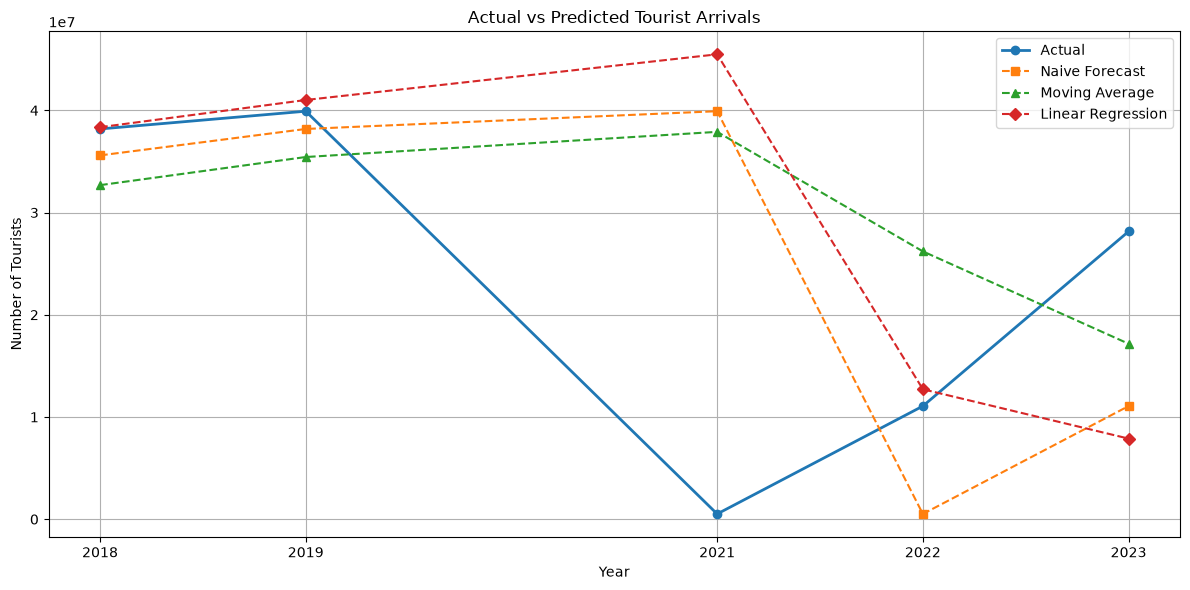

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# ค่าจริง
plt.plot(
    comparison["Year"],
    comparison["Actual"],
    marker="o",
    linewidth=2,
    label="Actual"
)

# ค่าพยากรณ์จาก Naive
plt.plot(
    comparison["Year"],
    comparison["Naive"],
    marker="s",
    linestyle="--",
    label="Naive Forecast"
)

# ค่าพยากรณ์จาก Moving Average
plt.plot(
    comparison["Year"],
    comparison["Moving_Average"],
    marker="^",
    linestyle="--",
    label="Moving Average"
)

# ค่าพยากรณ์จาก Linear Regression
plt.plot(
    comparison["Year"],
    comparison["Linear_Regression"],
    marker="D",
    linestyle="--",
    label="Linear Regression"
)

plt.xlabel("Year")
plt.ylabel("Number of Tourists")
plt.title("Actual vs Predicted Tourist Arrivals")
plt.legend()
plt.grid(True)
plt.xticks(comparison["Year"])
plt.tight_layout()
plt.show()

In [18]:
# คำนวณความคลาดเคลื่อนแบบค่าสัมบูรณ์
for name in [
    "Naive",
    "Moving_Average",
    "Linear_Regression"
]:
    comparison[name + "_Error"] = (
        comparison["Actual"] - comparison[name]
    ).abs()

print(comparison[[
    "Year",
    "Naive_Error",
    "Moving_Average_Error",
    "Linear_Regression_Error"
]].round(0))

   Year  Naive_Error  Moving_Average_Error  Linear_Regression_Error
0  2018      2586216             5496610.0                 172183.0
1  2019      1738057             4482998.0                1096340.0
2  2021     39405484            37384707.0               44970967.0
3  2022     10554459            15136511.0                1645651.0
4  2023     17084790            10985935.0               20266015.0


Intercept: 37042895.95116773
Slope: -2596063.309978769


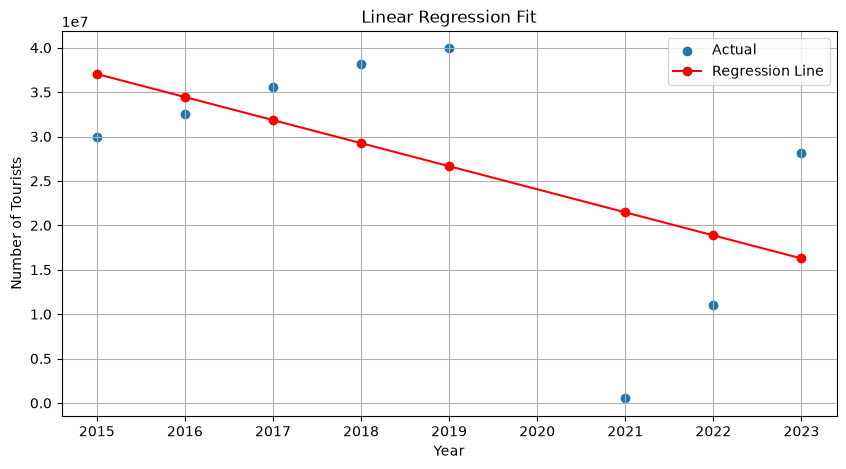

In [19]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

# เปลี่ยนปีให้เริ่มนับจาก 0 ในปี 2015
model_data["Year_Index"] = model_data["Year"] - 2015

X = model_data[["Year_Index"]]
y = model_data["Tourists"]

# สร้างโมเดลจากข้อมูลครบชุด
model = LinearRegression()
model.fit(X, y)

print("Intercept:", model.intercept_)
print("Slope:", model.coef_[0])

# ค่าที่โมเดลประมาณจากข้อมูลแต่ละปี
model_data["Fitted"] = model.predict(X)

# กราฟค่าจริงและค่าที่โมเดลประมาณ
plt.figure(figsize=(10, 5))

plt.scatter(
    model_data["Year"],
    model_data["Tourists"],
    label="Actual"
)

plt.plot(
    model_data["Year"],
    model_data["Fitted"],
    color="red",
    marker="o",
    label="Regression Line"
)

plt.xlabel("Year")
plt.ylabel("Number of Tourists")
plt.title("Linear Regression Fit")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. รวมจำนวนนักท่องเที่ยวตามปีและไตรมาส
quarter_total = df.groupby(
    ["Year", "Quarter"]
)["Number"].sum(min_count=1).reset_index()

quarter_total = quarter_total.sort_values(
    ["Year", "Quarter"]
)

print(quarter_total.head())

   Year  Quarter   Number
0  2015        1  7833277
1  2015        2  6977875
2  2015        3  7275824
3  2015        4  7836209
4  2016        1  9004203


In [21]:
# สร้างวันที่รายไตรมาส
quarter_total["Period"] = pd.PeriodIndex(
    quarter_total["Year"].astype(str)
    + "Q"
    + quarter_total["Quarter"].astype(str),
    freq="Q"
)

quarter_total = quarter_total.set_index("Period").sort_index()

# 3. เติมช่วงไตรมาสที่ขาดให้ครบ โดยให้ค่าที่ยังไม่มีเป็น NaN
all_quarters = pd.period_range(
    start=quarter_total.index.min(),
    end=quarter_total.index.max(),
    freq="Q"
)

quarter_total = quarter_total.reindex(all_quarters)
quarter_total.index.name = "Period"

# 4. เพิ่มคอลัมน์ปีและไตรมาส
quarter_total["Year"] = quarter_total.index.year
quarter_total["Quarter"] = quarter_total.index.quarter

# 5. พยากรณ์จากไตรมาสเดียวกันของปีก่อน
quarter_total["Forecast"] = quarter_total["Number"].shift(4)

print(
    quarter_total[
        ["Year", "Quarter", "Number", "Forecast"]
    ].tail(12)
)

        Year  Quarter     Number   Forecast
Period                                     
2021Q1  2021        1    38342.0  6691574.0
2021Q2  2021        2    34706.0        NaN
2021Q3  2021        3    65835.0        NaN
2021Q4  2021        4   371884.0    33619.0
2022Q1  2022        1   488118.0    38342.0
2022Q2  2022        2  1564658.0    34706.0
2022Q3  2022        3  3582421.0    65835.0
2022Q4  2022        4  5430029.0   371884.0
2023Q1  2023        1  6528231.0   488118.0
2023Q2  2023        2  6437153.0  1564658.0
2023Q3  2023        3  7089281.0  3582421.0
2023Q4  2023        4  8095351.0  5430029.0


In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# เลือกข้อมูลสำหรับทดสอบ เฉพาะปี 2022–2023
result = quarter_total[
    (quarter_total["Year"] >= 2022) &
    (quarter_total["Year"] <= 2023)
].dropna(subset=["Number", "Forecast"]).copy()

# แสดงค่าจริงและค่าพยากรณ์
print(result[["Year", "Quarter", "Number", "Forecast"]])

# คำนวณความคลาดเคลื่อน
mae = mean_absolute_error(
    result["Number"],
    result["Forecast"]
)

rmse = np.sqrt(mean_squared_error(
    result["Number"],
    result["Forecast"]
))

print("\nจำนวนไตรมาสที่ใช้ทดสอบ =", len(result))
print("MAE =", round(mae, 2))
print("RMSE =", round(rmse, 2))

        Year  Quarter     Number   Forecast
Period                                     
2022Q1  2022        1   488118.0    38342.0
2022Q2  2022        2  1564658.0    34706.0
2022Q3  2022        3  3582421.0    65835.0
2022Q4  2022        4  5430029.0   371884.0
2023Q1  2023        1  6528231.0   488118.0
2023Q2  2023        2  6437153.0  1564658.0
2023Q3  2023        3  7089281.0  3582421.0
2023Q4  2023        4  8095351.0  5430029.0

จำนวนไตรมาสที่ใช้ทดสอบ = 8
MAE = 3454906.12
RMSE = 3874926.46


In [25]:
from sklearn.metrics import r2_score

# เลือกข้อมูลที่มีทั้งค่าจริงและค่าพยากรณ์
valid = quarter_total[
    (quarter_total["Year"].isin([2022, 2023]))
].dropna(subset=["Number", "Forecast"]).copy()

# คำนวณ R-squared
r2 = r2_score(
    valid["Number"],
    valid["Forecast"]
)

print("Seasonal Naive R-squared =", round(r2, 4))

Seasonal Naive R-squared = -1.2826


In [32]:
import pandas as pd
import numpy as np
#Holt-Winters
q = quarter_total.copy()

if "Period" in q.columns:
    q = q.set_index("Period")

q = q.sort_index()

# เลือกข้อมูลตั้งแต่ปี 2015 ถึง 2021
train = q.loc["2015Q1":"2021Q4", "Number"].copy()

print(train)
print("จำนวนข้อมูลที่หายไป:", train.isna().sum())

Period
2015Q1     7833277.0
2015Q2     6977875.0
2015Q3     7275824.0
2015Q4     7836209.0
2016Q1     9004203.0
2016Q2     7509900.0
2016Q3     8249517.0
2016Q4     7765968.0
2017Q1     9181986.0
2017Q2     8184984.0
2017Q3     8887836.0
2017Q4     9337172.0
2018Q1    10578247.0
2018Q2     8847205.0
2018Q3     9042234.0
2018Q4     9710508.0
2019Q1    10792781.0
2019Q2     9010224.0
2019Q3     9705444.0
2019Q4    10407802.0
2020Q1     6691574.0
2020Q2           NaN
2020Q3           NaN
2020Q4       33619.0
2021Q1       38342.0
2021Q2       34706.0
2021Q3       65835.0
2021Q4      371884.0
Freq: Q-DEC, Name: Number, dtype: float64
จำนวนข้อมูลที่หายไป: 2


In [29]:
print(train[train.isna()])

Period
2020Q2   NaN
2020Q3   NaN
Freq: Q-DEC, Name: Number, dtype: float64


In [33]:
train_filled = train.interpolate(method="linear")

print(train_filled.loc["2020Q1":"2020Q4"])
print("จำนวนค่าที่หายหลังประมาณ:",
      train_filled.isna().sum())

Period
2020Q1    6.691574e+06
2020Q2    4.472256e+06
2020Q3    2.252937e+06
2020Q4    3.361900e+04
Freq: Q-DEC, Name: Number, dtype: float64
จำนวนค่าที่หายหลังประมาณ: 0


In [43]:
%pip install statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ------ --------------------------------- 1.8/11.3 MB 15.2 MB/s eta 0:00:01
   -------------------------------- ------- 9.2/11.3 MB 29.7 MB/s eta 0:00:01
   ---------------------------------------  11.3/11.3 MB 26.4 MB/s eta 0:00:01
   ---------------------------------------- 11.3/11.3 MB 17.1 MB/s  0:00:00

   -------- ------------------------------- 1/5 [patsy]
   -------- ------------------------------- 1/5 [patsy]
   ---------------- ----------------------- 2/5 [interface-meta]
   ------------------------ --------------- 3/5 [formulaic]
   ------------------------ --------------- 3/5 [formulaic]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   -------------------------------- ------- 4/5 [statsmodels]
   --------


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [44]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# เตรียมข้อมูลฝึก
train_filled = train.interpolate(method="linear")

# สร้างโมเดล Holt-Winters
model = ExponentialSmoothing(
    train_filled,
    trend="add",
    seasonal="add",
    seasonal_periods=4
)

fit = model.fit()

# พยากรณ์ 8 ไตรมาส สำหรับปี 2022–2023
forecast = fit.forecast(8)

# เลือกค่าจริงของช่วงทดสอบ
actual = q.loc["2022Q1":"2023Q4", "Number"]

# จัดให้ค่าจริงและค่าทำนายตรงกันตามไตรมาส
result = pd.concat(
    [actual.rename("Actual"),
     forecast.rename("Forecast")],
    axis=1
).dropna()

print(result)

# ประเมินความแม่นยำ
r2 = r2_score(result["Actual"], result["Forecast"])
mae = mean_absolute_error(result["Actual"], result["Forecast"])
rmse = np.sqrt(mean_squared_error(
    result["Actual"], result["Forecast"]
))

print("R-squared =", round(r2, 4))
print("MAE =", round(mae, 2))
print("RMSE =", round(rmse, 2))

ImportError: DLL load failed while importing _conventional: An Application Control policy has blocked this file.

In [46]:
import sys
print(sys.version)

import numpy
import scipy
import pandas

print("NumPy:", numpy.__version__)
print("SciPy:", scipy.__version__)
print("Pandas:", pandas.__version__)

3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]
NumPy: 2.5.4
SciPy: 1.18.1
Pandas: 3.0.6


In [49]:
!python -m pip show statsmodels

Name: statsmodels
Version: 0.15.0
Summary: Statistical computations and models for Python
Home-page: https://www.statsmodels.org
Author: 
Author-email: 
License-Expression: BSD-3-Clause
Location: c:\Users\supin\AppData\Local\Programs\Python\Python314\Lib\site-packages
Requires: formulaic, numpy, packaging, pandas, patsy, scipy
Required-by: 


In [51]:
from sklearn.linear_model import LinearRegression

print("scikit-learn ใช้งานได้")

scikit-learn ใช้งานได้


In [53]:
import pandas as pd
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# ข้อมูลรายปีที่เคยสรุปไว้
annual = pd.DataFrame({
    "Year": [2015, 2016, 2017, 2018, 2019,
             2020, 2021, 2022, 2023],
    "Tourists": [29923185, 32529588, 35591978,
                 38178194, 39916251, 6725193,
                 510767, 11065226, 28150016]
})

# แบ่งข้อมูลฝึกและข้อมูลทดสอบ
train = annual[annual["Year"] <= 2021].copy()
test = annual[annual["Year"] >= 2022].copy()

# ใช้ปีเป็นตัวแปร X และจำนวนนักท่องเที่ยวเป็น y
X_train = train[["Year"]]
y_train = train["Tourists"]
X_test = test[["Year"]]
y_test = test["Tourists"]

# สร้างโมเดล Polynomial Regression ระดับ 2
model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

model.fit(X_train, y_train)

# พยากรณ์
predicted = model.predict(X_test)

# ประเมินผล
print("Actual:", y_test.tolist())
print("Predicted:", np.round(predicted).astype(int).tolist())
print("R-squared:", round(r2_score(y_test, predicted), 4))
print("MAE:", round(mean_absolute_error(y_test, predicted), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predicted)), 2))

Actual: [11065226, 28150016]
Predicted: [6813768, 1960898]
R-squared: -3.8234
MAE: 15220288.02
RMSE: 18760927.21


In [55]:
print(quarter_total[["Year", "Quarter", "Number"]].tail(16))

        Year  Quarter     Number
Period                          
2020Q1  2020        1  6691574.0
2020Q2  2020        2        NaN
2020Q3  2020        3        NaN
2020Q4  2020        4    33619.0
2021Q1  2021        1    38342.0
2021Q2  2021        2    34706.0
2021Q3  2021        3    65835.0
2021Q4  2021        4   371884.0
2022Q1  2022        1   488118.0
2022Q2  2022        2  1564658.0
2022Q3  2022        3  3582421.0
2022Q4  2022        4  5430029.0
2023Q1  2023        1  6528231.0
2023Q2  2023        2  6437153.0
2023Q3  2023        3  7089281.0
2023Q4  2023        4  8095351.0


In [56]:
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# ใช้ข้อมูลรายไตรมาสที่มีค่าจริง
q = quarter_total.copy()
data = q.dropna(subset=["Number"]).copy()

# สร้างตัวแปรลำดับเวลา
data["Time"] = np.arange(len(data))

# แบ่งข้อมูลฝึกและข้อมูลทดสอบ
train = data[data["Year"] <= 2021]
test = data[data["Year"].isin([2022, 2023])]

X_train = train[["Time"]]
y_train = train["Number"]

X_test = test[["Time"]]
y_test = test["Number"]

# สร้าง Polynomial Regression ระดับ 2
model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

model.fit(X_train, y_train)
predicted = model.predict(X_test)

print("R-squared:", round(r2_score(y_test, predicted), 4))
print("MAE:", round(mean_absolute_error(y_test, predicted), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predicted)), 2))

R-squared: -32.5407
MAE: 13255600.37
RMSE: 14853556.28


In [58]:
print(data[["Year", "Quarter", "Number", "Time"]].tail(20))

        Year  Quarter      Number  Time
Period                                 
2018Q3  2018        3   9042234.0    14
2018Q4  2018        4   9710508.0    15
2019Q1  2019        1  10792781.0    16
2019Q2  2019        2   9010224.0    17
2019Q3  2019        3   9705444.0    18
2019Q4  2019        4  10407802.0    19
2020Q1  2020        1   6691574.0    20
2020Q4  2020        4     33619.0    21
2021Q1  2021        1     38342.0    22
2021Q2  2021        2     34706.0    23
2021Q3  2021        3     65835.0    24
2021Q4  2021        4    371884.0    25
2022Q1  2022        1    488118.0    26
2022Q2  2022        2   1564658.0    27
2022Q3  2022        3   3582421.0    28
2022Q4  2022        4   5430029.0    29
2023Q1  2023        1   6528231.0    30
2023Q2  2023        2   6437153.0    31
2023Q3  2023        3   7089281.0    32
2023Q4  2023        4   8095351.0    33


In [60]:
# เรียงข้อมูลตามไตรมาส
q = quarter_total.copy().sort_index()

# สร้างลำดับเวลาจากไตรมาสจริงก่อนตัดแถวที่ไม่มีค่า
q["Time"] = np.arange(len(q))

# ตัดเฉพาะแถวที่ไม่มีจำนวนจริง
data = q.dropna(subset=["Number"]).copy()

print(data[["Year", "Quarter", "Number", "Time"]].tail(20))

        Year  Quarter      Number  Time
Period                                 
2018Q3  2018        3   9042234.0    14
2018Q4  2018        4   9710508.0    15
2019Q1  2019        1  10792781.0    16
2019Q2  2019        2   9010224.0    17
2019Q3  2019        3   9705444.0    18
2019Q4  2019        4  10407802.0    19
2020Q1  2020        1   6691574.0    20
2020Q4  2020        4     33619.0    23
2021Q1  2021        1     38342.0    24
2021Q2  2021        2     34706.0    25
2021Q3  2021        3     65835.0    26
2021Q4  2021        4    371884.0    27
2022Q1  2022        1    488118.0    28
2022Q2  2022        2   1564658.0    29
2022Q3  2022        3   3582421.0    30
2022Q4  2022        4   5430029.0    31
2023Q1  2023        1   6528231.0    32
2023Q2  2023        2   6437153.0    33
2023Q3  2023        3   7089281.0    34
2023Q4  2023        4   8095351.0    35


In [69]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# แบ่งข้อมูลฝึกและข้อมูลทดสอบ
train = data[data["Year"] <= 2021].copy()
test = data[data["Year"].isin([2022, 2023])].copy()

X_train = train[["Time"]]
y_train = train["Number"]
X_test = test[["Time"]]
y_test = test["Number"]

# Polynomial Regression ระดับ 4
model = make_pipeline(
    PolynomialFeatures(degree=4, include_bias=False),
    LinearRegression()
)

model.fit(X_train, y_train)
predicted = model.predict(X_test)

# แสดงผล
result = test[["Year", "Quarter", "Number"]].copy()
result["Forecast"] = predicted

print(result)
print("R-squared:", round(r2_score(y_test, predicted), 4))
print("MAE:", round(mean_absolute_error(y_test, predicted), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predicted)), 2))

        Year  Quarter     Number      Forecast
Period                                        
2022Q1  2022        1   488118.0 -1.607050e+06
2022Q2  2022        2  1564658.0 -1.795728e+06
2022Q3  2022        3  3582421.0 -1.580666e+06
2022Q4  2022        4  5430029.0 -8.779890e+05
2023Q1  2023        1  6528231.0  4.019406e+05
2023Q2  2023        2  6437153.0  2.354526e+06
2023Q3  2023        3  7089281.0  5.080934e+06
2023Q4  2023        4  8095351.0  8.688097e+06
R-squared: -1.674
MAE: 3717083.85
RMSE: 4193962.49


In [71]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# แบ่งข้อมูลฝึกและข้อมูลทดสอบ
train = data[data["Year"] <= 2021].copy()
test = data[data["Year"].isin([2022, 2023])].copy()

# เลือกตัวแปร
X_train = train[["Time"]]
y_train = train["Number"]

X_test = test[["Time"]]
y_test = test["Number"]

# สร้างโมเดล Polynomial Regression ระดับ 4
model = make_pipeline(
    PolynomialFeatures(degree=4, include_bias=False),
    LinearRegression()
)

# ฝึกโมเดลด้วย Training data
model.fit(X_train, y_train)

# ทำนายผลของ Training data
train_predicted = model.predict(X_train)

# คำนวณ R-squared จาก Training data เท่านั้น
r2_train = r2_score(y_train, train_predicted)

print("Training R-squared:", round(r2_train, 4))

Training R-squared: 0.8803


In [73]:
model2 = make_pipeline(
    PolynomialFeatures(degree=4, include_bias=False),
    LinearRegression()
)

model2.fit(X_train, y_train)

test_predicted = model2.predict(X_test)

print(
    "Testing R-squared:",
    round(r2_score(y_test, test_predicted), 4)
)

Testing R-squared: -1.674


In [75]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# สร้างโมเดล Polynomial Regression ระดับ 4
model4 = make_pipeline(
    PolynomialFeatures(degree=4, include_bias=False),
    LinearRegression()
)

# ฝึกโมเดลด้วยข้อมูล Training
model4.fit(X_train, y_train)

# ทำนายข้อมูล Testing
test_predicted = model4.predict(X_test)

# สร้างตารางเปรียบเทียบ
result4 = test[["Year", "Quarter", "Number"]].copy()
result4["Forecast"] = test_predicted
result4["Error"] = result4["Number"] - result4["Forecast"]

print(result4.round(2))


        Year  Quarter     Number    Forecast       Error
Period                                                  
2022Q1  2022        1   488118.0 -1607049.95  2095167.95
2022Q2  2022        2  1564658.0 -1795728.46  3360386.46
2022Q3  2022        3  3582421.0 -1580665.96  5163086.96
2022Q4  2022        4  5430029.0  -877989.01  6308018.01
2023Q1  2023        1  6528231.0   401940.57  6126290.43
2023Q2  2023        2  6437153.0  2354525.65  4082627.35
2023Q3  2023        3  7089281.0  5080933.83  2008347.17
2023Q4  2023        4  8095351.0  8688097.44  -592746.44


In [77]:
mae = mean_absolute_error(y_test, test_predicted)

rmse = np.sqrt(
    mean_squared_error(y_test, test_predicted)
)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

MAE: 3717083.85
RMSE: 4193962.49


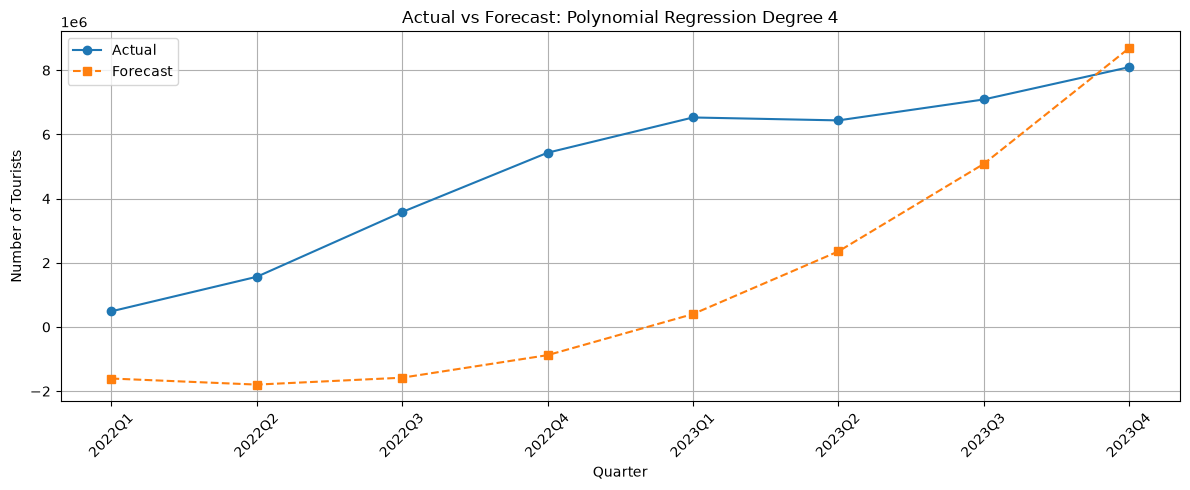

In [83]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    test.index.astype(str),
    y_test,
    marker="o",
    label="Actual"
)

plt.plot(
    test.index.astype(str),
    test_predicted,
    marker="s",
    linestyle="--",
    label="Forecast"
)

plt.title("Actual vs Forecast: Polynomial Regression Degree 4")
plt.xlabel("Quarter")
plt.ylabel("Number of Tourists")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [85]:
#ใช้อันนี้แทน

In [81]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# ใช้ข้อมูลช่วงปี 2021–2022 ฝึกโมเดล
train_recovery = data[
    data["Year"].isin([2021, 2022])
].copy()

# ใช้ข้อมูลปี 2023 ทดสอบโมเดล
test_recovery = data[
    data["Year"] == 2023
].copy()

# เลือกตัวแปร
X_train_r = train_recovery[["Time"]]
y_train_r = train_recovery["Number"]

X_test_r = test_recovery[["Time"]]
y_test_r = test_recovery["Number"]

# สร้างและฝึก Linear Regression
model_linear = LinearRegression()
model_linear.fit(X_train_r, y_train_r)

# คำนวณค่าพยากรณ์
train_pred_r = model_linear.predict(X_train_r)
test_pred_r = model_linear.predict(X_test_r)

# คำนวณ R-squared
print("Training R-squared:",
      round(r2_score(y_train_r, train_pred_r), 4))

print("Testing R-squared:",
      round(r2_score(y_test_r, test_pred_r), 4))

# คำนวณความคลาดเคลื่อน
print("MAE:",
      round(mean_absolute_error(y_test_r, test_pred_r), 2))

print("RMSE:",
      round(np.sqrt(mean_squared_error(y_test_r, test_pred_r)), 2))

Training R-squared: 0.7569
Testing R-squared: -3.1408
MAE: 1298141.52
RMSE: 1342691.0


In [86]:
result_linear = test_recovery[
    ["Year", "Quarter", "Number"]
].copy()

result_linear["Forecast"] = test_pred_r
result_linear["Error"] = (
    result_linear["Number"] - result_linear["Forecast"]
)

print(result_linear.round(2))

        Year  Quarter     Number    Forecast       Error
Period                                                  
2023Q1  2023        1  6528231.0  4666271.64  1861959.36
2023Q2  2023        2  6437153.0  5381665.54  1055487.46
2023Q3  2023        3  7089281.0  6097059.43   992221.57
2023Q4  2023        4  8095351.0  6812453.32  1282897.68


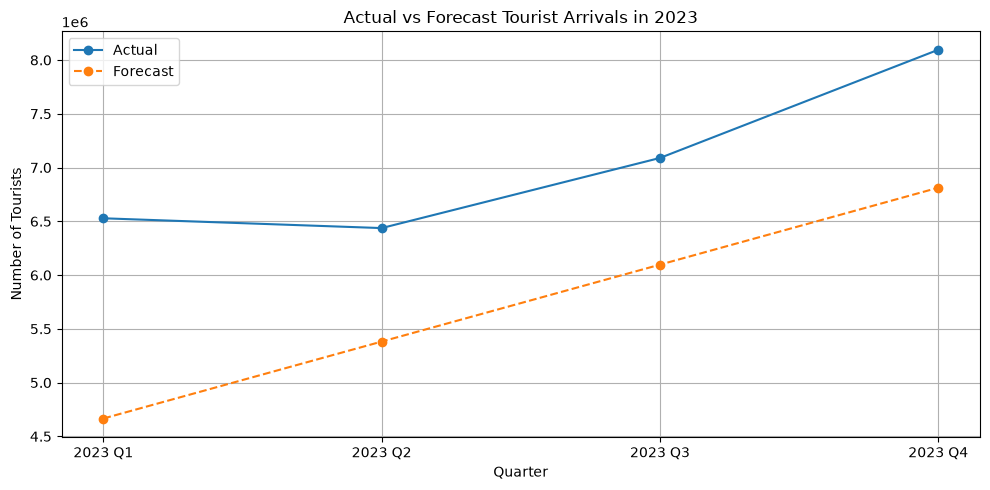

In [88]:

import matplotlib.pyplot as plt

# สร้างชื่อไตรมาส เช่น 2023 Q1, 2023 Q2
labels = (
    test_recovery["Year"].astype(str)
    + " Q"
    + test_recovery["Quarter"].astype(str)
)

# วาดกราฟเปรียบเทียบ
plt.figure(figsize=(10, 5))

plt.plot(
    labels, test_recovery["Number"],
    marker="o", label="Actual"
)

plt.plot(
    labels, test_pred_r,
    marker="o", linestyle="--", label="Forecast"
)

plt.title("Actual vs Forecast Tourist Arrivals in 2023")
plt.xlabel("Quarter")
plt.ylabel("Number of Tourists")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [90]:

import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.pipeline import make_pipeline
import numpy as np

# แบ่งข้อมูล Train และ Test เหมือนกันทุกโมเดล
train = data[data["Year"] <= 2021].copy()
test = data[data["Year"].isin([2022, 2023])].copy()

X_train = train[["Time"]]
y_train = train["Number"]

X_test = test[["Time"]]
y_test = test["Number"]

# สร้างโมเดล 3 แบบ
models = {
    "Linear Regression": make_pipeline(
        PolynomialFeatures(degree=1, include_bias=False),
        LinearRegression()
    ),
    "Polynomial Degree 2": make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        LinearRegression()
    ),
    "Polynomial Degree 4": make_pipeline(
        PolynomialFeatures(degree=4, include_bias=False),
        LinearRegression()
    )
}

results = []

# ฝึกและประเมินแต่ละโมเดล
for name, model in models.items():
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Training R2": r2_score(y_train, train_pred),
        "Testing R2": r2_score(y_test, test_pred),
        "MAE": mean_absolute_error(y_test, test_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, test_pred))
    })

# แสดงตารางเปรียบเทียบ
results_df = pd.DataFrame(results)
print(results_df.round(4))


                 Model  Training R2  Testing R2           MAE          RMSE
0    Linear Regression       0.3534     -1.6196  3.684079e+06  4.151054e+06
1  Polynomial Degree 2       0.8116    -31.5339  1.317278e+07  1.462893e+07
2  Polynomial Degree 4       0.8803     -1.6740  3.717084e+06  4.193962e+06


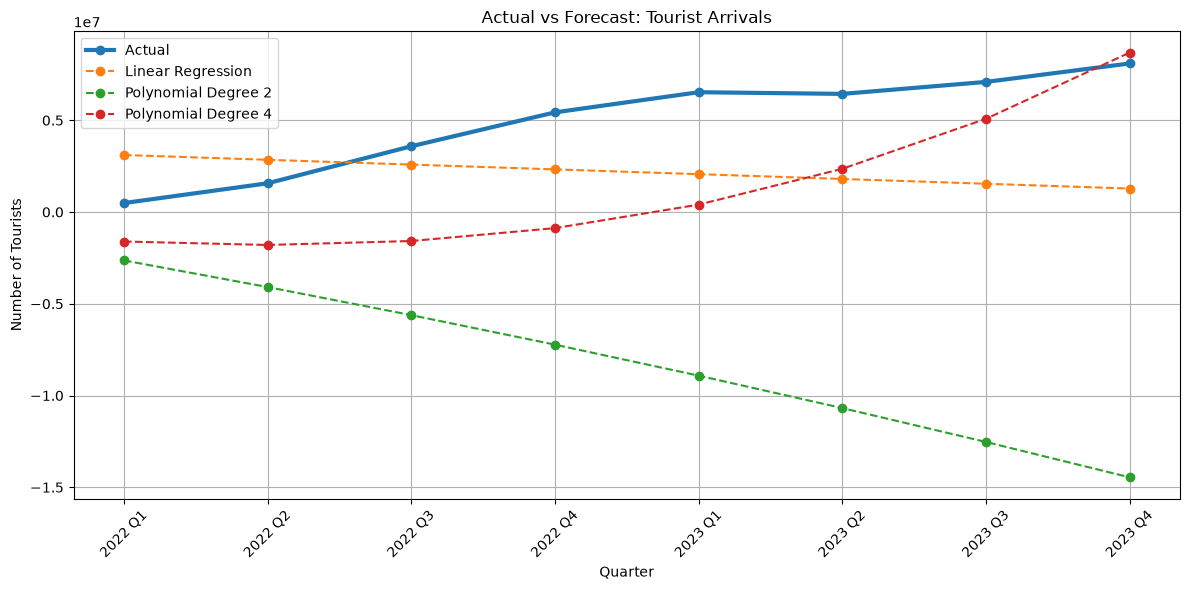

In [92]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

# เส้นจำนวนจริง
labels = test["Year"].astype(str) + " Q" + test["Quarter"].astype(str)

plt.plot(
    labels, test["Number"],
    marker="o", linewidth=3, label="Actual"
)

# เส้นค่าพยากรณ์ของแต่ละโมเดล
for name, model in models.items():
    forecast = model.predict(test[["Time"]])

    plt.plot(
        labels, forecast,
        marker="o", linestyle="--",
        label=name
    )

plt.title("Actual vs Forecast: Tourist Arrivals")
plt.xlabel("Quarter")
plt.ylabel("Number of Tourists")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [94]:

# สร้างตารางเปรียบเทียบค่าจริงกับค่าพยากรณ์
forecast_table = test[["Year", "Quarter", "Number"]].copy()

for name, model in models.items():
    forecast = model.predict(test[["Time"]])

    forecast_table[name] = forecast
    forecast_table[name + " Error"] = (
        test["Number"] - forecast
    ).abs()

# เปลี่ยนชื่อคอลัมน์ให้อ่านง่าย
forecast_table = forecast_table.rename(
    columns={"Number": "Actual"}
)

print(forecast_table.round(2).to_string(index=False))


 Year  Quarter    Actual  Linear Regression  Linear Regression Error  Polynomial Degree 2  Polynomial Degree 2 Error  Polynomial Degree 4  Polynomial Degree 4 Error
 2022        1  488118.0         3106368.52               2618250.52          -2638148.52                 3126266.52          -1607049.95                 2095167.95
 2022        2 1564658.0         2845275.46               1280617.46          -4088854.77                 5653512.77          -1795728.46                 3360386.46
 2022        3 3582421.0         2584182.39                998238.61          -5618883.01                 9201304.01          -1580665.96                 5163086.96
 2022        4 5430029.0         2323089.33               3106939.67          -7228233.26                12658262.26           -877989.01                 6308018.01
 2023        1 6528231.0         2061996.26               4466234.74          -8916905.50                15445136.50            401940.57                 6126290.43
 2023     

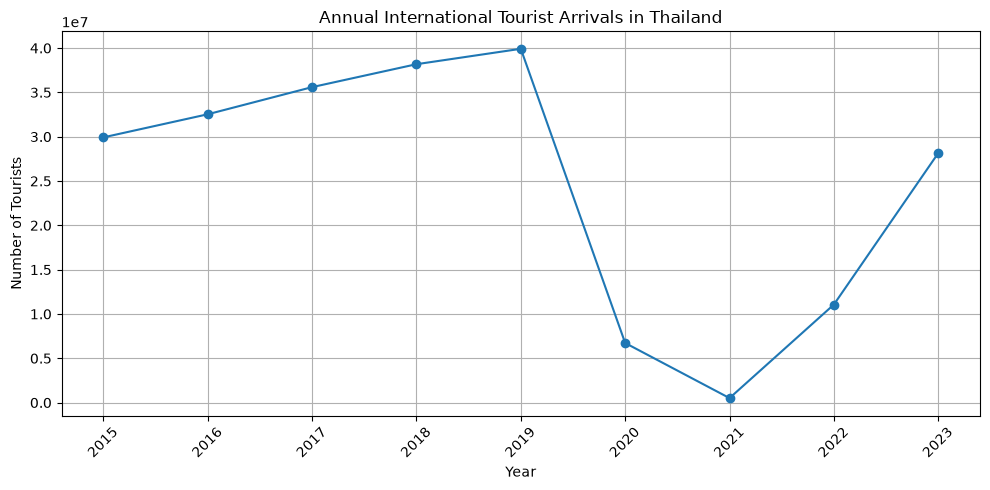

In [97]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    year_total.index,
    year_total.values,
    marker="o"
)

plt.title("Annual International Tourist Arrivals in Thailand")
plt.xlabel("Year")
plt.ylabel("Number of Tourists")
plt.xticks(year_total.index, rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [98]:

# สร้างตารางสรุปผลรายปี
year_summary = year_total.reset_index()
year_summary.columns = ["Year", "Number"]

# คำนวณจำนวนที่เปลี่ยนแปลงจากปีก่อน
year_summary["Change"] = year_summary["Number"].diff()

# คำนวณเปอร์เซ็นต์การเปลี่ยนแปลง
year_summary["Change_Percent"] = (
    year_summary["Number"].pct_change() * 100
)

print(year_summary.round(2).to_string(index=False))


 Year   Number      Change  Change_Percent
 2015 29923185         NaN             NaN
 2016 32529588   2606403.0            8.71
 2017 35591978   3062390.0            9.41
 2018 38178194   2586216.0            7.27
 2019 39916251   1738057.0            4.55
 2020  6725193 -33191058.0          -83.15
 2021   510767  -6214426.0          -92.41
 2022 11065226  10554459.0         2066.39
 2023 28150016  17084790.0          154.40


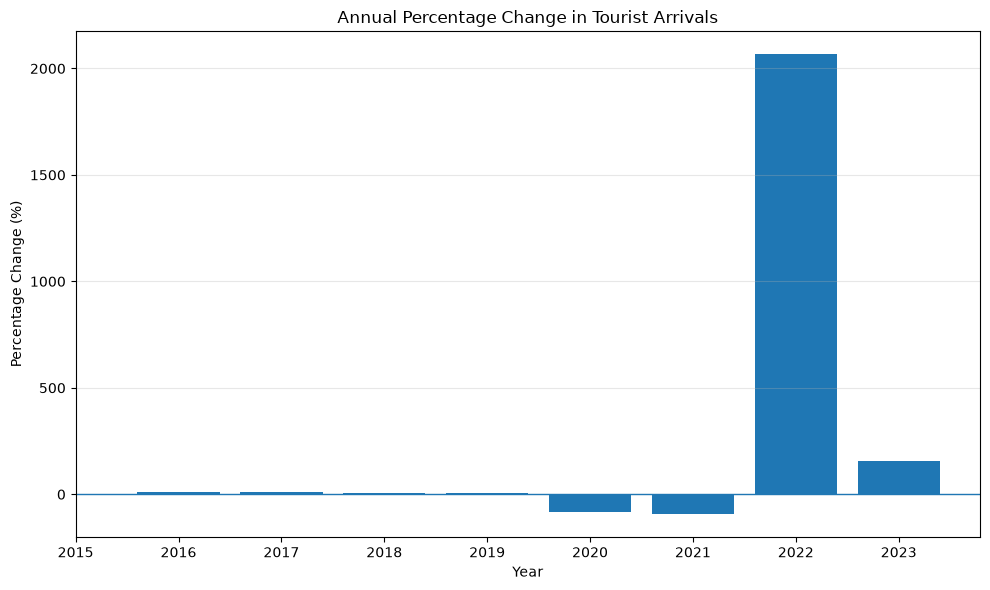

In [102]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    year_summary["Year"],
    year_summary["Change_Percent"]
)

plt.axhline(y=0, linewidth=1)
plt.title("Annual Percentage Change in Tourist Arrivals")
plt.xlabel("Year")
plt.ylabel("Percentage Change (%)")
plt.xticks(year_summary["Year"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [104]:

# ข้อ2
country_total = df.groupby("Country")["Number"].sum(min_count=1)

country_total = country_total.sort_values(ascending=False)

top10_country = country_total.head(10)

print(top10_country)


Country
China                           53479693
Malaysia                        25920714
Korea (Republic of)             10645325
India                            9808617
Laos                             9666414
Japan                            9154044
Russian Federation               8779274
Singapore                        7593754
The United States of America     6625567
Vietnam                          6376779
Name: Number, dtype: int64


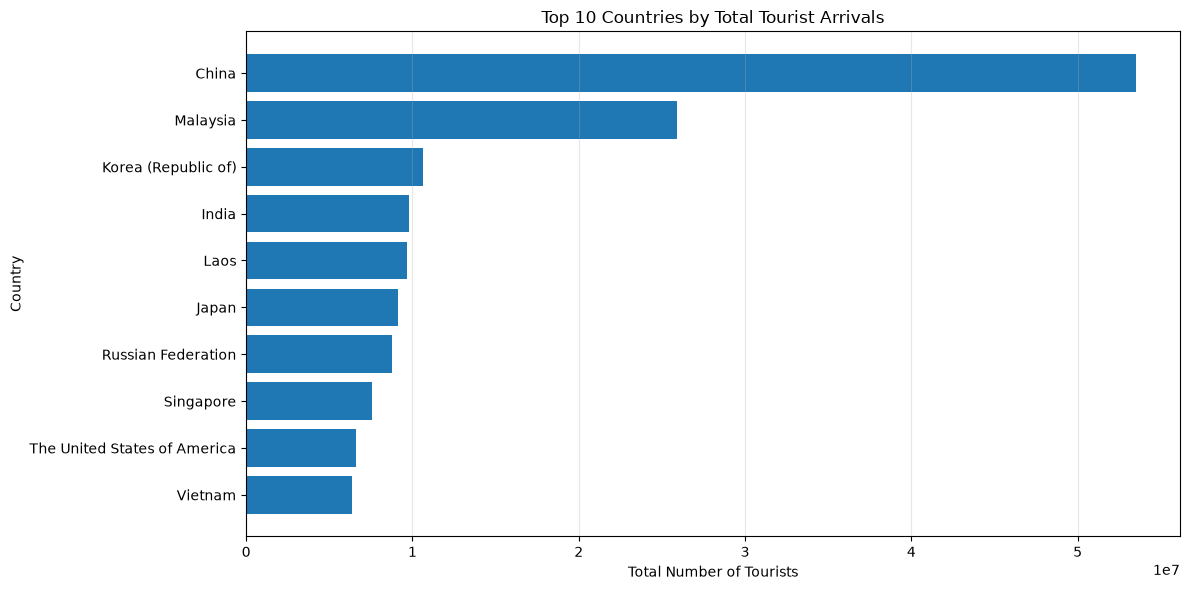

In [106]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.barh(top10_country.index[::-1], top10_country.values[::-1])

plt.title("Top 10 Countries by Total Tourist Arrivals")
plt.xlabel("Total Number of Tourists")
plt.ylabel("Country")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [108]:
#ข้อ3
df_top10 = df[df["Country"].isin(top10_country.index)]

country_stats = df_top10.groupby("Country")["Number"].agg(
    ["mean", "std"]
)

country_stats = country_stats.sort_values(
    by="mean", ascending=False
)

print(country_stats.round(2))


                                   mean        std
Country                                           
China                         524310.72  381315.18
Malaysia                      254124.65  139981.57
Korea (Republic of)           104365.93   60834.94
India                          96162.91   53733.67
Laos                           94768.76   54869.78
Japan                          89745.53   55389.04
Russian Federation             86071.31   70361.11
Singapore                      74448.57   41132.64
The United States of America   64956.54   35214.54
Vietnam                        62517.44   36216.67


<Figure size 1600x700 with 0 Axes>

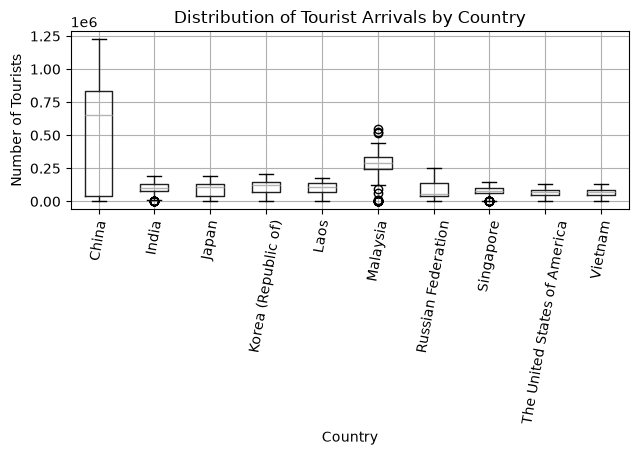

In [114]:

plt.figure(figsize=(16, 7))

df_top10.boxplot(
    column="Number",
    by="Country",
    rot=80
)

plt.title("Distribution of Tourist Arrivals by Country")
plt.suptitle("")
plt.xlabel("Country")
plt.ylabel("Number of Tourists")
plt.tight_layout()
plt.show()
